1.b

Código do projeto anterior na 5.a:

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

def movimentoAntigo(N, A, x0, v0, t, k=1.0, m=1.0):
    autovalores, autovetores = autovaloresAutovetores(A)

    a = np.dot(autovetores.T, x0.T)
    b = np.dot(autovetores.T, v0.T)
    
    x_t = np.zeros((N, len(t)))
    v_t = np.zeros((N, len(t)))

    for i in range(N):
        lmb = autovalores[i]
        
        if lmb < 1e-10:
            for j in range(len(t)):
                q_t = a[i] + b[i] * t[j]
                dq_t = b[i]
                x_t[:, j] += autovetores[:, i] * q_t
                v_t[:, j] += autovetores[:, i] * dq_t
        else:
            w = np.sqrt(lmb * (k / m))
            for j in range(len(t)):
                q_t = a[i] * np.cos(w * t[j]) + (b[i] / w) * np.sin(w * t[j])
                dq_t = -a[i] * w * np.sin(w * t[j]) + b[i] * np.cos(w * t[j])
                x_t[:, j] += autovetores[:, i] * q_t
                v_t[:, j] += autovetores[:, i] * dq_t

    return x_t, v_t

def matrizSegundaLei(N, kList, k):
  A0 = np.zeros((N, N))
  V = np.zeros((N, N))
  Mid = np.eye(N)  

  for i in range(N):
    for j in range(N):

      A0[i][j] = (
          2 * Mid[i][j] - (Mid[i][j + 1] if j + 1 < N else 0) - (Mid[i][j - 1] if j - 1 >= 0 else 0) - Mid[i][0] * Mid[j][0] - Mid[i][N - 1] * Mid[j][N - 1]
      )
      
      V[i][j] = (kList[i] / k) * Mid[i][j]

  A = A0 + V
  return A

def autovaloresAutovetores(A):
    eigenvalues, eigenvectors = np.linalg.eigh(A)
    
    return eigenvalues, eigenvectors

1.b

Código adaptado para receber, também, $\vec{u}$ e retornar $\vec{x}$ e $\vec{v}$.

In [7]:
def movimento(N, A, x0, v0, u, t, k=1.0, m=1.0):

    y0 = x0 - u
    
    autovalores, autovetores = autovaloresAutovetores(A)
    
    a = np.dot(autovetores.T, y0.T)
    b = np.dot(autovetores.T, v0.T) # a velocidade n muda pois se derivar uma vez o u some
    
    y_t = np.zeros((N, len(t)))
    v_t = np.zeros((N, len(t)))

    for i in range(N):
        lmb = autovalores[i]
        
        if lmb < 1e-10:
            for j in range(len(t)):
                q_t = a[i] + b[i] * t[j]
                dq_t = b[i]
                y_t[:, j] += autovetores[:, i] * q_t
                v_t[:, j] += autovetores[:, i] * dq_t
        else:
            w = np.sqrt(lmb * (k / m))
            for j in range(len(t)):
                q_t = a[i] * np.cos(w * t[j]) + (b[i] / w) * np.sin(w * t[j])
                dq_t = -a[i] * w * np.sin(w * t[j]) + b[i] * np.cos(w * t[j])
                y_t[:, j] += autovetores[:, i] * q_t
                v_t[:, j] += autovetores[:, i] * dq_t

    return y_t + u.reshape(N,1), v_t

def montarAr(N, kmuro, k = 1.0):
    A0 = matrizSegundaLei(N, np.zeros(N), k)
    xNxNT = np.zeros((N,N))
    xNxNT[N-1][N-1] = 1
    
    Ar = A0 + kmuro/k * (xNxNT)

1.c

In [8]:
def movimento(N, A, x0, v0, u, t, k=1.0, m=1.0):
  t = np.atleast_1d(t)
  y0 = x0 - u

  autovalores, autovetores = autovaloresAutovetores(A)

  a = np.dot(autovetores.T, y0.T)
  b = np.dot(autovetores.T, v0.T)

  y_t = np.zeros((N, len(t)))
  v_t = np.zeros((N, len(t)))

  for i in range(N):
    lmb = autovalores[i]

    if lmb < 1e-10:
      for j in range(len(t)):
        q_t = a[i] + b[i] * t[j]
        dq_t = b[i]
        y_t[:, j] += autovetores[:, i] * q_t
        v_t[:, j] += autovetores[:, i] * dq_t
    else:
      w = np.sqrt(lmb * (k / m))
      for j in range(len(t)):
        q_t = a[i] * np.cos(w * t[j]) + (b[i] / w) * np.sin(w * t[j])
        dq_t = -a[i] * w * np.sin(w * t[j]) + b[i] * np.cos(w * t[j])
        y_t[:, j] += autovetores[:, i] * q_t
        v_t[:, j] += autovetores[:, i] * dq_t

  return y_t + u.reshape(N, 1), v_t


def montarAr(N, kmuro, k=1.0):
  A0 = matrizSegundaLei(N, np.zeros(N), k)
  xNxNT = np.zeros((N, N))
  xNxNT[N - 1][N - 1] = 1
  return A0 + (kmuro / k) * xNxNT


def montarAl(N, kmuro, k=1.0):
  A0 = matrizSegundaLei(N, np.zeros(N), k)
  x1x1T = np.zeros((N, N))
  x1x1T[0][0] = 1
  return A0 + (kmuro / k) * x1x1T


def primeira_raiz_grid(func_escalar, valores_grid, t_grid, direcao):
  """
    Busca em grade (grid-search) o primeiro intervalo [t_j, t_{j+1}] onde
    a função muda de sinal na direção esperada e refina a raiz com brentq.
      direcao = +1 : cruza de negativo para positivo
      direcao = -1 : cruza de positivo para negativo
    """
  for j in range(len(t_grid) - 1):
    v1, v2 = valores_grid[j], valores_grid[j + 1]
    if direcao == 1 and (v1 < 0 and v2 >= 0):
      return brentq(func_escalar, t_grid[j], t_grid[j + 1], xtol=1e-12)
    elif direcao == -1 and (v1 > 0 and v2 <= 0):
      return brentq(func_escalar, t_grid[j], t_grid[j + 1], xtol=1e-12)
  return None


def simular_caixa(
    N, x0, v0, d, kmuro, t_max, k=1.0, m=1.0, fase_inicial="livre"
):
  A0 = matrizSegundaLei(N, np.zeros(N), k)
  Ar = montarAr(N, kmuro, k)
  Al = montarAl(N, kmuro, k)

  # Passo da grade: 1/25 do menor período possível do sistema
  omega_max = np.sqrt((k / m) * (4.0 + kmuro / k))
  T_min = 2.0 * np.pi / omega_max
  dt = T_min / 25.0

  fase = fase_inicial
  t_atual = 0.0
  x_atual = x0.copy()
  v_atual = v0.copy()

  historico_t = []
  historico_x = []
  historico_v = []

  while t_atual < t_max - 1e-12:
    t_restante = t_max - t_atual

    if fase == "livre":
      A = A0
      u = np.zeros(N)
    elif fase == "direita":
      A = Ar
      u = np.full(N, d)
    elif fase == "esquerda":
      A = Al
      u = np.full(N, -d)

    # Monta a grade começando em dt para evitar a raiz trivial em t = 0
    if t_restante > dt:
      n_pontos = max(int(np.ceil(t_restante / dt)) + 1, 2)
      t_grid = np.linspace(dt, t_restante, n_pontos)
    else:
      t_grid = np.array([t_restante])

    # Avalia x(t) em toda a grade de uma só vez
    x_grid, _ = movimento(N, A, x_atual, v_atual, u, t_grid, k, m)

    # Verificação de segurança contra a 4ª fase (contato simultâneo)
    if np.any((x_grid[0, :] < -d) & (x_grid[-1, :] > d)):
      raise RuntimeError(
          "4ª fase atingida (contato simultâneo)! Aumente a folga d."
      )

    t_evento = None
    proxima_fase = None

    if fase == "livre":
      # 1) Possível colisão à direita: x_N(t) - d = 0 (subindo)
      fR_esc = (
          lambda ts: movimento(N, A, x_atual, v_atual, u, ts, k, m)[0][-1, 0]
          - d
      )
      t_R = primeira_raiz_grid(fR_esc, x_grid[-1, :] - d, t_grid, direcao=+1)

      # 2) Possível colisão à esquerda: x_1(t) + d = 0 (descendo)
      fL_esc = (
          lambda ts: movimento(N, A, x_atual, v_atual, u, ts, k, m)[0][0, 0] + d
      )
      t_L = primeira_raiz_grid(fL_esc, x_grid[0, :] + d, t_grid, direcao=-1)

      # Prevalece o evento que ocorrer primeiro
      if t_R is not None and (t_L is None or t_R <= t_L):
        t_evento = t_R
        proxima_fase = "direita"
      elif t_L is not None:
        t_evento = t_L
        proxima_fase = "esquerda"

    elif fase == "direita":
      # Descolamento à direita: x_N(t) - d = 0 (descendo)
      fR_esc = (
          lambda ts: movimento(N, A, x_atual, v_atual, u, ts, k, m)[0][-1, 0]
          - d
      )
      t_evento = primeira_raiz_grid(
          fR_esc, x_grid[-1, :] - d, t_grid, direcao=-1
      )
      proxima_fase = "livre"

    elif fase == "esquerda":
      # Descolamento à esquerda: x_1(t) + d = 0 (subindo)
      fL_esc = (
          lambda ts: movimento(N, A, x_atual, v_atual, u, ts, k, m)[0][0, 0] + d
      )
      t_evento = primeira_raiz_grid(
          fL_esc, x_grid[0, :] + d, t_grid, direcao=+1
      )
      proxima_fase = "livre"

    # Define a duração da fase atual
    if t_evento is None or t_evento > t_restante:
      t_duracao = t_restante
      houve_transicao = False
    else:
      t_duracao = t_evento
      houve_transicao = True

    # Calcula e armazena a trajetória completa da fase atual
    n_save = max(int(np.ceil(t_duracao / dt)) + 1, 2)
    t_local = np.linspace(0.0, t_duracao, n_save)
    x_fase, v_fase = movimento(N, A, x_atual, v_atual, u, t_local, k, m)

    if len(historico_t) > 0:
      historico_t.append(t_atual + t_local[1:])
      historico_x.append(x_fase[:, 1:])
      historico_v.append(v_fase[:, 1:])
    else:
      historico_t.append(t_atual + t_local)
      historico_x.append(x_fase)
      historico_v.append(v_fase)

    # Atualiza estado para o próximo ciclo
    t_atual += t_duracao
    x_atual = x_fase[:, -1]
    v_atual = v_fase[:, -1]

    if houve_transicao:
      print(
          f"t = {t_atual:7.4f}s | {fase:8s} -> {proxima_fase:8s} | x1 ="
          f" {x_atual[0]:+.4f}, xN = {x_atual[-1]:+.4f}"
      )
      fase = proxima_fase

  return (
      np.concatenate(historico_t),
      np.hstack(historico_x),
      np.hstack(historico_v),
  )

<>:15: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:15: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/tmp/ipykernel_50334/4184964559.py:15: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.axhline(d, color="r", linestyle="--", label="Paredes ($\pm d$)")


t =  6.0000s | livre    -> direita  | x1 = +6.0000, xN = +6.0000
t =  6.4489s | direita  -> livre    | x1 = +6.4489, xN = +6.0000
t =  8.2001s | livre    -> direita  | x1 = +8.2001, xN = +6.0000
t =  8.6665s | direita  -> livre    | x1 = +8.6665, xN = +6.0000
t = 10.5866s | livre    -> direita  | x1 = +10.5866, xN = +6.0000
t = 11.0515s | direita  -> livre    | x1 = +11.0514, xN = +6.0000
t = 12.9713s | livre    -> direita  | x1 = +12.9586, xN = +6.0000
t = 13.4357s | direita  -> livre    | x1 = +13.4026, xN = +6.0000
t = 15.3286s | livre    -> direita  | x1 = +14.6950, xN = +6.0000
t = 15.7931s | direita  -> livre    | x1 = +14.7242, xN = +6.0000
t = 17.6815s | livre    -> direita  | x1 = +13.0660, xN = +6.0000
t = 18.1462s | direita  -> livre    | x1 = +12.3948, xN = +6.0000
t = 20.0469s | livre    -> direita  | x1 = +10.3130, xN = +6.0000
t = 20.5114s | direita  -> livre    | x1 = +9.9539, xN = +6.0000
t = 22.4337s | livre    -> direita  | x1 = +8.0092, xN = +6.0000
t = 22.8953s | d

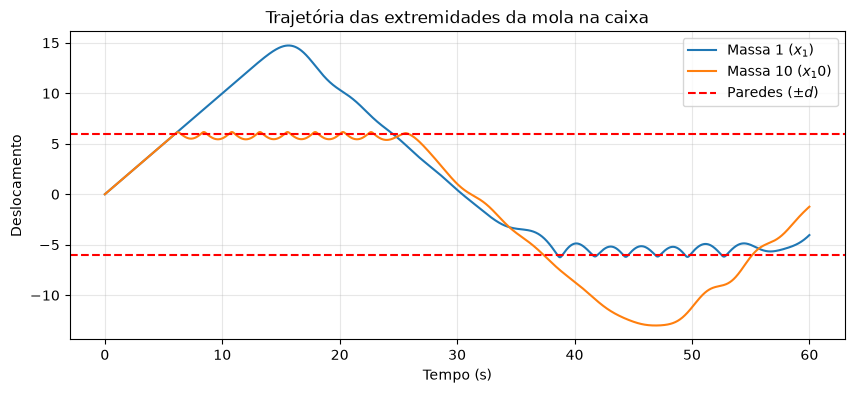

In [ ]:
N = 10
k = 1.0
m = 1.0
kmuro = 100.0
d = 6.0

x0 = np.zeros(N)
v0 = np.ones(N)

t_tot, x_tot, v_tot = simular_caixa(N, x0, v0, d, kmuro, t_max=60.0, k=k, m=m)

plt.figure(figsize=(10, 4))
plt.plot(t_tot, x_tot[0, :], label="Massa 1 ($x_1$)")
plt.plot(t_tot, x_tot[-1, :], label=f"Massa {N} ($x_{N}$)")
plt.axhline(d, color="r", linestyle="--", label="Paredes ($\pm d$)")
plt.axhline(-d, color="r", linestyle="--")
plt.xlabel("Tempo (s)")
plt.ylabel("Deslocamento")
plt.title("Trajetória das extremidades da mola na caixa")
plt.legend()
plt.grid(True, alpha=0.3)


plt.show()

1.d

In [18]:
# Código reaproveitado da atividade passada com modificações

def energiaMec(N, x_t, v_t, t, d, kmuro, k=1.0, m=1.0):
  energia = np.zeros((N, len(t)))

  for j in range(len(t)):
    for i in range(N):
      e_cin = 0.5 * m * (v_t[i, j] ** 2)

      e_pot_interna = 0.0
      if i < N - 1:
        e_pot_interna = 0.5 * k * ((x_t[i + 1, j] - x_t[i, j]) ** 2)

      e_pot_muro = 0.0
      if i == 0 and x_t[0, j] < -d:
        e_pot_muro = 0.5 * kmuro * ((x_t[0, j] + d) ** 2)
      if i == N - 1 and x_t[N - 1, j] > d:
        e_pot_muro = 0.5 * kmuro * ((x_t[N - 1, j] - d) ** 2)

      energia[i, j] = e_cin + e_pot_interna + e_pot_muro

  return energia


energiaM = energiaMec(N, x_tot, v_tot, t_tot, d, kmuro, k, m)

E_total = np.sum(energiaM, axis=0)

print("Energia inicial:", E_total[0])
print("Energia final  :", E_total[-1])
print("Variação máxima:", np.max(np.abs(E_total - E_total[0])))

Energia inicial: 5.0
Energia final  : 5.000000000000013
Variação máxima: 1.0835776720341528e-13


1.e

Animação das massas

In [19]:
from IPython.display import HTML
from matplotlib import animation
import matplotlib.pyplot as plt
import numpy as np


def anima_caixa(
    x_t, t, d, L=1.0, titulo="Mola macroscópica na caixa", passo=5
):
  """
    Anima as N massas se movendo entre duas paredes separadas por folgas d.

    x_t   : array (N, nt) com o deslocamento x_i(t) de cada massa
    t     : array (nt,) com os instantes correspondentes
    d     : folga inicial entre as pontas e as paredes
    L     : espaçamento de equilíbrio entre massas vizinhas
    passo : usa 1 a cada 'passo' quadros de t (acelera e reduz o tamanho da animação)
    """
  N, nt = x_t.shape
  idx = np.arange(0, nt, passo)
  pos_eq = np.arange(1, N + 1) * L  # posições de equilíbrio: L, 2L, ..., N*L

  # Posições reais das paredes esquerda e direita
  parede_esq = L - d
  parede_dir = N * L + d

  fig, ax = plt.subplots(figsize=(10, 2.6))

  # Ajusta xlim para caber toda a caixa e a compressão nas paredes
  x_min = min(parede_esq, np.min(pos_eq[0] + x_t[0, :])) - 0.5 * L
  x_max = max(parede_dir, np.max(pos_eq[-1] + x_t[-1, :])) + 0.5 * L
  ax.set_xlim(x_min, x_max)
  ax.set_ylim(-0.6, 0.6)
  ax.set_yticks([])
  ax.set_xlabel("posição ao longo da reta")
  ax.set_title(titulo)

  # Desenha as paredes e preenche a região externa
  ax.axvline(parede_esq, color="k", lw=3, zorder=2)
  ax.axvline(parede_dir, color="k", lw=3, zorder=2)
  ax.axvspan(x_min, parede_esq, color="lightgray", alpha=0.5)
  ax.axvspan(parede_dir, x_max, color="lightgray", alpha=0.5)

  # Elementos gráficos animados
  (linha_molas,) = ax.plot([], [], "-", color="tab:gray", lw=1.5, zorder=1)
  (mola_esq,) = ax.plot([], [], "-", color="tab:orange", lw=3.0, zorder=2)
  (mola_dir,) = ax.plot([], [], "-", color="tab:orange", lw=3.0, zorder=2)
  pontos = ax.scatter(
      pos_eq, np.zeros(N), s=120, color="tab:blue", edgecolor="k", zorder=3
  )
  tempo_txt = ax.text(0.02, 0.85, "", transform=ax.transAxes)

  def init():
    linha_molas.set_data([], [])
    mola_esq.set_data([], [])
    mola_dir.set_data([], [])
    pontos.set_offsets(np.column_stack([pos_eq, np.zeros(N)]))
    tempo_txt.set_text("")
    return linha_molas, mola_esq, mola_dir, pontos, tempo_txt

  def update(frame):
    j = idx[frame]
    xpos = pos_eq + x_t[:, j]
    pontos.set_offsets(np.column_stack([xpos, np.zeros(N)]))
    linha_molas.set_data(xpos, np.zeros(N))

    # Ativa o desenho da mola da parede (laranja) apenas durante o contato
    if x_t[0, j] < -d:
      mola_esq.set_data([parede_esq, xpos[0]], [0, 0])
    else:
      mola_esq.set_data([], [])

    if x_t[-1, j] > d:
      mola_dir.set_data([xpos[-1], parede_dir], [0, 0])
    else:
      mola_dir.set_data([], [])

    tempo_txt.set_text(f"t = {t[j]:.2f} s")
    return linha_molas, mola_esq, mola_dir, pontos, tempo_txt

  anim = animation.FuncAnimation(
      fig, update, frames=len(idx), init_func=init, interval=30, blit=True
  )
  plt.close(fig)
  return anim

In [20]:
anim = anima_caixa(x_tot, t_tot, d=d, L=1.0, passo=4)
HTML(anim.to_jshtml())